Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step - accuracy: 0.4114 - loss: 1.6397 - val_accuracy: 0.5165 - val_loss: 1.3724
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 24s 38ms/step - accuracy: 0.5157 - loss: 1.3585 - val_accuracy: 0.5603 - val_loss: 1.2571
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 24s 38ms/step - accuracy: 0.5607 - loss: 1.2443 - val_accuracy: 0.5414 - val_loss: 1.3595
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 40s 36ms/step - accuracy: 0.5800 - loss: 1.1850 - val_accuracy: 0.5991 - val_loss: 1.1362
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.5994 - loss: 1.1396 - val_accuracy: 0.6270 - val_loss: 1.0620
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 23s 36ms/step - accuracy: 0.6165 - loss: 1.0936 - val_accuracy: 0.6403 - val_loss: 1.0392
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.6268 - loss: 1.0615 - val_accuracy: 0.6146 - val_loss: 1.1128
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 26s 42ms/step - accuracy: 0.6367 - loss: 1.0372 - 

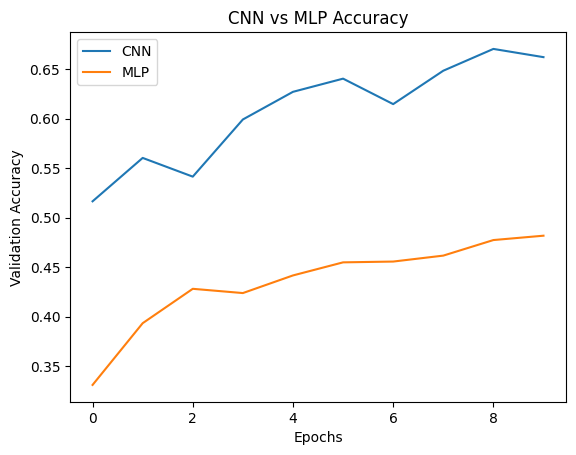

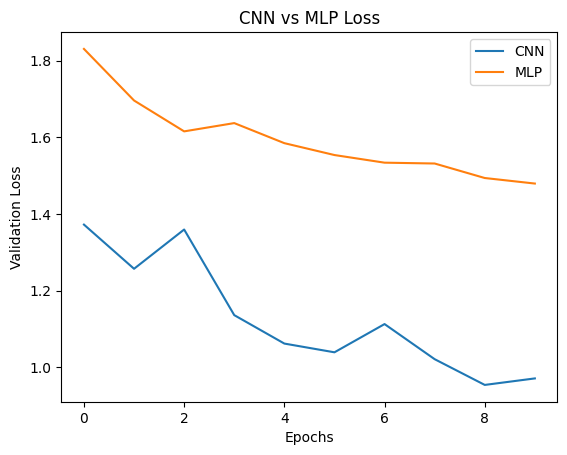

In [1]:
# Step 1: Import Libraries
import tensorflow as tf
import matplotlib.pyplot as plt

# Step 2: Load CIFAR-10 Dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Step 3: Normalize Data
x_train, x_test = x_train / 255.0, x_test / 255.0

# Step 4: Data Augmentation
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1)
])

# Step 5: Build CNN Model
cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    augmentation,
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Step 6: Compile CNN
cnn.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])

# Step 7: Train CNN
history_cnn = cnn.fit(x_train, y_train, epochs=10,
                      validation_split=0.2, batch_size=64)

# Step 8: Evaluate CNN
cnn_loss, cnn_acc = cnn.evaluate(x_test, y_test)
print("CNN Test Accuracy:", cnn_acc)

# Step 9: Build MLP Model
mlp = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Step 10: Compile MLP
mlp.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])

# Step 11: Train MLP
history_mlp = mlp.fit(x_train, y_train, epochs=10,
                      validation_split=0.2, batch_size=64)

# Step 12: Evaluate MLP
mlp_loss, mlp_acc = mlp.evaluate(x_test, y_test)
print("MLP Test Accuracy:", mlp_acc)

# Step 13: Compare CNN and MLP
print("\nPerformance Comparison")
print("CNN Accuracy:", cnn_acc)
print("MLP Accuracy:", mlp_acc)

# Step 14: Plot Accuracy Comparison
plt.plot(history_cnn.history['val_accuracy'], label='CNN')
plt.plot(history_mlp.history['val_accuracy'], label='MLP')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.title('CNN vs MLP Accuracy')
plt.legend()
plt.show()

# Step 15: Plot Loss Comparison
plt.plot(history_cnn.history['val_loss'], label='CNN')
plt.plot(history_mlp.history['val_loss'], label='MLP')
plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.title('CNN vs MLP Loss')
plt.legend()
plt.show()

Training Data: (60000, 28, 28, 1)
Testing Data: (10000, 28, 28, 1)
Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 56s 58ms/step - accuracy: 0.9352 - loss: 0.2107 - val_accuracy: 0.9818 - val_loss: 0.0628
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 77s 52ms/step - accuracy: 0.9778 - loss: 0.0723 - val_accuracy: 0.9865 - val_loss: 0.0486
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 81s 51ms/step - accuracy: 0.9834 - loss: 0.0536 - val_accuracy: 0.9898 - val_loss: 0.0341
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 55ms/step - accuracy: 0.9853 - loss: 0.0455 - val_accuracy: 0.9920 - val_loss: 0.0325
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 56ms/step - accuracy: 0.9887 - loss: 0.0367 - val_accuracy: 0.9905 - val_loss: 0.0372
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 56ms/step - accuracy: 0.9899 - loss: 0.0315 - val_accuracy: 0.9917 - val_loss: 0.0355
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 54ms/step - accuracy: 0.9910 - loss: 0.0276 - val_accuracy: 0.9903 - val_loss: 0.0380
Epoch 8/10
844/844 ━━━━

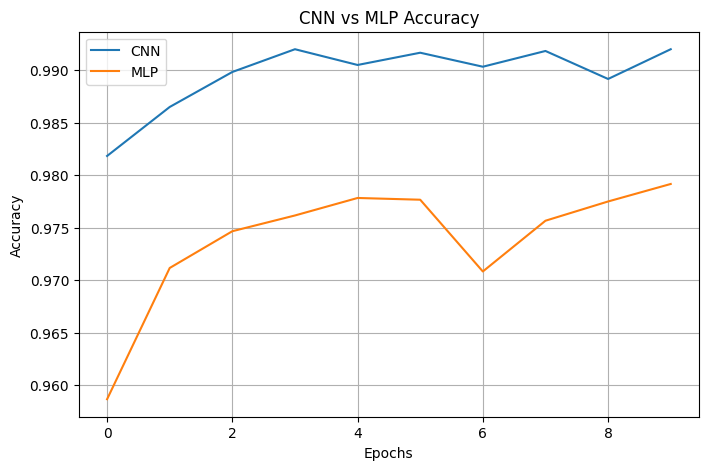

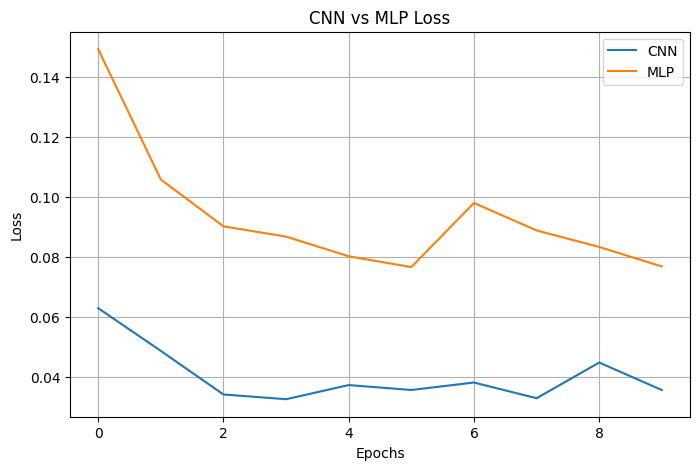

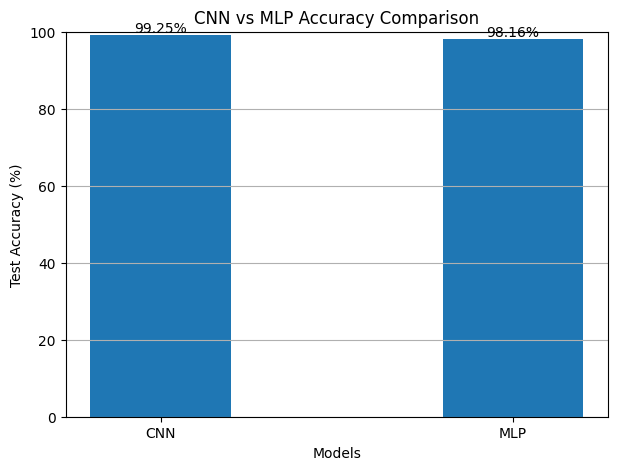

In [2]:
# Step 1: Import Libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

# Step 2: Load Local MNIST Dataset
path = "mnist"

x_train = np.fromfile(os.path.join(path, "train-images-idx3-ubyte"),
                      dtype=np.uint8, offset=16).reshape(-1, 28, 28, 1)

y_train = np.fromfile(os.path.join(path, "train-labels-idx1-ubyte"),
                      dtype=np.uint8, offset=8)

x_test = np.fromfile(os.path.join(path, "t10k-images-idx3-ubyte"),
                     dtype=np.uint8, offset=16).reshape(-1, 28, 28, 1)

y_test = np.fromfile(os.path.join(path, "t10k-labels-idx1-ubyte"),
                     dtype=np.uint8, offset=8)

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

# Step 3: Normalize Data
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Step 4: Data Augmentation
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1)
])

# Step 5: Build CNN Model
cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    augmentation,
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Step 6: Compile CNN
cnn.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])

# Step 7: Train CNN
history_cnn = cnn.fit(x_train, y_train, epochs=10,
                      batch_size=64, validation_split=0.1)

# Step 8: Build MLP Model
mlp = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Step 9: Compile MLP
mlp.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])

# Step 10: Train MLP
history_mlp = mlp.fit(x_train, y_train, epochs=10,
                      batch_size=64, validation_split=0.1)

# Step 11: Evaluate Both Models
cnn_loss, cnn_acc = cnn.evaluate(x_test, y_test)
mlp_loss, mlp_acc = mlp.evaluate(x_test, y_test)

print("\nCNN Test Accuracy:", cnn_acc)
print("MLP Test Accuracy:", mlp_acc)

# Step 12: Plot Accuracy Comparison
plt.figure(figsize=(8, 5))
plt.plot(history_cnn.history['val_accuracy'], label='CNN')
plt.plot(history_mlp.history['val_accuracy'], label='MLP')
plt.title('CNN vs MLP Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

# Step 13: Plot Loss Comparison
plt.figure(figsize=(8, 5))
plt.plot(history_cnn.history['val_loss'], label='CNN')
plt.plot(history_mlp.history['val_loss'], label='MLP')
plt.title('CNN vs MLP Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(7, 5))

models = ['CNN', 'MLP']
accuracy = [cnn_acc * 100, mlp_acc * 100]

plt.bar(models, accuracy, width=0.4)

plt.title('CNN vs MLP Accuracy Comparison')
plt.xlabel('Models')
plt.ylabel('Test Accuracy (%)')
plt.ylim(0, 100)

for i, v in enumerate(accuracy):
    plt.text(i, v + 0.5, f'{v:.2f}%', ha='center')

plt.grid(axis='y')
plt.show()

Training Data: (60000, 28, 28)
Testing Data: (10000, 28, 28)
Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 85s 87ms/step - accuracy: 0.9334 - loss: 0.2138 - val_accuracy: 0.9822 - val_loss: 0.0589
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 71s 84ms/step - accuracy: 0.9771 - loss: 0.0735 - val_accuracy: 0.9868 - val_loss: 0.0412
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 73s 87ms/step - accuracy: 0.9833 - loss: 0.0536 - val_accuracy: 0.9890 - val_loss: 0.0390
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 65s 77ms/step - accuracy: 0.9857 - loss: 0.0459 - val_accuracy: 0.9908 - val_loss: 0.0361
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 71s 64ms/step - accuracy: 0.9883 - loss: 0.0385 - val_accuracy: 0.9910 - val_loss: 0.0388
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 71s 84ms/step - accuracy: 0.9889 - loss: 0.0346 - val_accuracy: 0.9897 - val_loss: 0.0365
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 80s 95ms/step - accuracy: 0.9900 - loss: 0.0310 - val_accuracy: 0.9905 - val_loss: 0.0321
Epoch 8/10
844/844 ━━━━━━━━━━

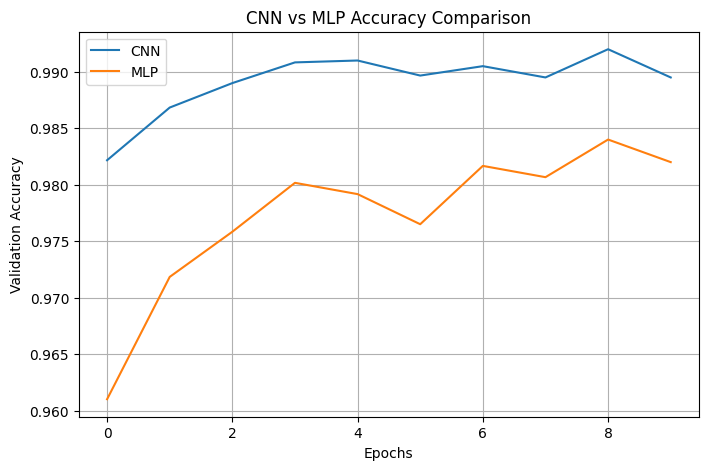

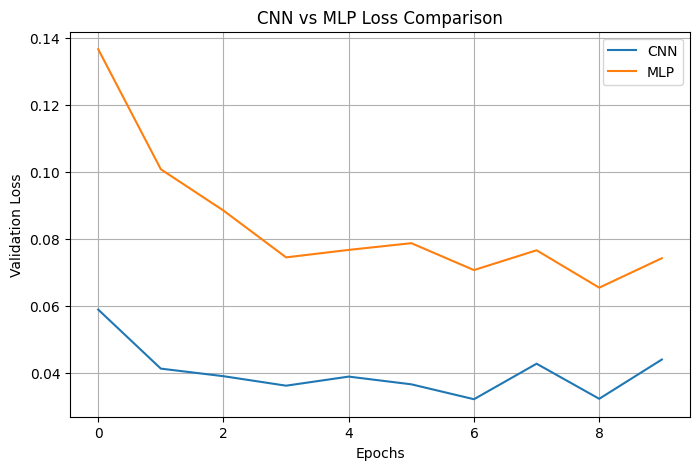

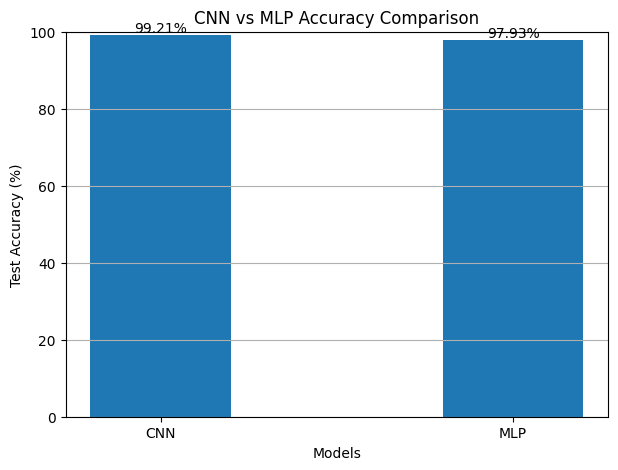


Final Performance Comparison
CNN Accuracy: 99.21 %
MLP Accuracy: 97.93 %
CNN Loss: 0.0242
MLP Loss: 0.0695


In [1]:
# Step 1: Import Libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Step 2: Load Local MNIST Dataset
data = np.load('mnist.npz')

x_train = data['x_train']
y_train = data['y_train']
x_test = data['x_test']
y_test = data['y_test']

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

# Step 3: Normalize Data
x_train = x_train.reshape(-1, 28, 28, 1).astype('float32') / 255.0
x_test = x_test.reshape(-1, 28, 28, 1).astype('float32') / 255.0

# Step 4: Data Augmentation
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1)
])

# Step 5: Build CNN Model
cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    augmentation,
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Step 6: Compile CNN
cnn.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])

# Step 7: Train CNN
history_cnn = cnn.fit(x_train, y_train,
                      epochs=10,
                      batch_size=64,
                      validation_split=0.1)

# Step 8: Build MLP Model
mlp = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Step 9: Compile MLP
mlp.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])

# Step 10: Train MLP
history_mlp = mlp.fit(x_train, y_train,
                      epochs=10,
                      batch_size=64,
                      validation_split=0.1)

# Step 11: Evaluate CNN
cnn_loss, cnn_acc = cnn.evaluate(x_test, y_test)
print("\nCNN Test Accuracy:", cnn_acc)

# Step 12: Evaluate MLP
mlp_loss, mlp_acc = mlp.evaluate(x_test, y_test)
print("MLP Test Accuracy:", mlp_acc)

# Step 13: Plot Accuracy Comparison
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history['val_accuracy'], label='CNN')
plt.plot(history_mlp.history['val_accuracy'], label='MLP')

plt.title('CNN vs MLP Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid()
plt.show()

# Step 14: Plot Loss Comparison
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history['val_loss'], label='CNN')
plt.plot(history_mlp.history['val_loss'], label='MLP')

plt.title('CNN vs MLP Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid()
plt.show()

# Step 15: Final Accuracy Comparison (Bar Graph)
plt.figure(figsize=(7, 5))

models = ['CNN', 'MLP']
accuracy = [cnn_acc * 100, mlp_acc * 100]

plt.bar(models, accuracy, width=0.4)

plt.title('CNN vs MLP Accuracy Comparison')
plt.xlabel('Models')
plt.ylabel('Test Accuracy (%)')
plt.ylim(0, 100)

for i, v in enumerate(accuracy):
    plt.text(i, v + 0.5, f'{v:.2f}%', ha='center')

plt.grid(axis='y')
plt.show()

# Step 16: Print Final Results
print("\nFinal Performance Comparison")
print("CNN Accuracy:", round(cnn_acc * 100, 2), "%")
print("MLP Accuracy:", round(mlp_acc * 100, 2), "%")
print("CNN Loss:", round(cnn_loss, 4))
print("MLP Loss:", round(mlp_loss, 4))